# Notebook 1 -- Contexte industriel et comprehension des donnees
### Reconstruction d'un capteur de vibration industriel momentanement indisponible

> ****Note de provenance.**** Les notebooks de recherche originaux seront présents dans le répertoire du projet, accompagnés des données et des fichiers nécessaires aux expériences. Le présent notebook fait uniquement office de **notebook d'analyse et de synthèse** : il ne remplace pas les notebooks originaux et ne constitue pas une nouvelle implémentation des expérimentations.
>
> Le code, les résultats et les sorties présentés dans ce notebook sont analysés à partir des travaux réalisés dans les notebooks originaux. Aucun résultat n'a été recalculé ni inventé : lorsqu'une information n'était pas déterminable à partir des notebooks ou des données disponibles, cela est signalé explicitement plutôt que comblé. Ce notebook n'est donc pas conçu pour être exécuté isolément de haut en bas ; il a pour objectif de **documenter, structurer, comparer et interpréter les résultats déjà obtenus**, ainsi que de mettre en évidence la progression scientifique entre les différentes approches étudiées.


## Objectif

Ce premier notebook ne teste aucun modele. Il pose le probleme scientifique du memoire et etablit
les faits empiriques de base sur les donnees -- capteurs disponibles, valeurs manquantes
preexistantes, structure temporelle, redondance apparente entre capteurs -- qui justifieront le
choix des methodes explorees dans les notebooks suivants. La question a laquelle il repond est :
*que sait-on des donnees avant de tenter quoi que ce soit ?*

## Motivation

Une machine industrielle est instrumentee par plusieurs capteurs de vibration. Un capteur peut
cesser temporairement de transmettre (panne reseau, perte de communication, defaillance materielle
ou logicielle, perte de paquets). Le probleme devient critique lorsque cette absence survient
precisement au moment d'un evenement vibratoire important (choc, vibration anormale, transitoire,
apparition soudaine d'un defaut) : si le capteur defaillant est celui qui aurait du mesurer cet
evenement, l'anomalie peut ne pas etre detectee, avec un risque de detection tardive, d'absence
d'alarme, voire de panne aggravee. Le probleme scientifique du memoire est donc : **comment
reconstruire ou predire de maniere fiable le signal vibratoire d'un capteur momentanement
indisponible a partir des informations fournies par les autres capteurs de la machine ?**

Une difficulte structure toute l'analyse qui suit : la reconstruction ne doit pas seulement
reproduire la *forme* generale du signal, elle doit aussi reproduire correctement son *amplitude*,
en particulier pendant les evenements transitoires ou anormaux. Cette distinction entre
reconstruction de la dynamique et reconstruction de l'amplitude sera le fil conducteur de
l'ensemble des notebooks.

## Hypothese

Les differents capteurs etant installes sur la meme machine, leurs signaux ne sont pas
independants : ils peuvent partager des excitations communes, des dynamiques mecaniques communes,
des modes vibratoires communs, des phenomenes de propagation, des correlations physiques et/ou
statistiques. L'hypothese initiale (H0), qui structure toute la demarche qui suit, est donc :

> **Les capteurs disponibles peuvent contenir suffisamment d'information pour reconstruire le
> signal d'un capteur devenu indisponible.**

Ce notebook rassemble les elements empiriques permettant de juger si cette hypothese est au moins
plausible avant d'investir dans des methodes de plus en plus sophistiquees.

## Methodologie

Deux fichiers de donnees pretraitees apparaissent dans le corpus de notebooks original, et cette
reorganisation le documente plutot que de l'effacer :

- **`preprocessed_data.csv`** (16 626 lignes, colonnes `Timestamp`, `equipment_id`, `ACR_Mot.PV`,
  `ACR_Mot.SV`, `ACR_Mot.TV`, `ACR_Pmp.PV`, `ACR_Pmp.SV`, `ACR_Pmp.TV`, `Pres.PV`, `Temp.PV`,
  `Barometer`, `Temperature`) est utilise dans ce notebook ainsi que dans les notebooks 2, 4 et 5
  (piste SSI + SINDy + Kalman). Le decoupage Train/Validation/Test y est **temporel global**
  (70 % / 15 % / 15 %), sans distinction explicite entre equipements.
- **`preprocessed_data1.csv`** (15 686 lignes, memes colonnes, 3 equipements `A`/`B`/`C`) est
  utilise dans les notebooks 6 et 7 (piste XGBoost), avec un decoupage **par equipement**
  (60 % / 20 % / 20 % au sein de chaque equipement, puis recombinaison).

Cet ecart entre les deux jeux de donnees existe dans le corpus original ; il n'a pas ete
harmonise ici et constitue une limite methodologique explicite (section *Limites* ci-dessous) :
les resultats des notebooks 1-5 et ceux des notebooks 6-7 ne sont donc pas obtenus sur exactement
le meme perimetre de donnees.

Le capteur cible retenu dans l'ensemble du corpus est **`ACR_Mot.PV`** : c'est lui qui sera
artificiellement masque pour simuler une panne et evaluer chaque methode de reconstruction.

### Chargement et premiere inspection (`preprocessed_data.csv`)

In [ ]:
# ============================== CONFIGURATION ==============================
import warnings
warnings.filterwarnings("ignore")

DATA_PATH = "../data/processed/preprocessed_data.csv"   # <-- chemin vers votre CSV (relatif, à adapter)

TIME_COLUMN = "Timestamp"        # nom de la colonne temporelle. Mettre None si pas de colonne temps explicite (index = temps).
TARGET_SENSOR = "ACR_Mot.PV"       # nom du capteur à reconstruire (celui qui sera artificiellement masqué pour l'évaluation)
AVAILABLE_SENSORS = None         # liste des colonnes capteurs à utiliser. None => toutes les colonnes numériques sauf TIME_COLUMN.

# Fraction train / validation / test (split temporel, PAS de shuffle)
TRAIN_FRAC = 0.70
VAL_FRAC   = 0.15
TEST_FRAC  = 0.15   

# SSI
SSI_BLOCK_ROWS = 15          # nombre de block-rows "s" (doit être > ordre max testé)
SSI_ORDER_CANDIDATES = [2, 3, 4, 5, 6, 8]   # ordres testés, choisis via validation

# SINDy
SINDY_POLY_DEGREE = 2
SINDY_THRESHOLD_CANDIDATES = [0.01, 0.02, 0.05, 0.1, 0.2]   # sparsité, choisi via validation
SINDY_ALPHA = 0.05

# Kalman / EKF
EKF_Q_SCALE = 1e-3     # covariance de bruit de process (échelle)
EKF_R_SCALE = 1e-2     # covariance de bruit de mesure (échelle)

# Tests de manquants
RANDOM_MISSING_FRACTION = 0.10
CONTINUOUS_WINDOW_FRACTIONS = [0.01, 0.05, 0.10, 0.20, 0.30]
PEAK_WINDOW_HALF_WIDTH = 15     # nb d'échantillons de part et d'autre d'un pic à masquer
LONG_WINDOW_FRACTIONS = [0.30, 0.45, 0.60]

RANDOM_SEED = 42

OUTPUT_DIR = "results"    # dossier où sauver les CSV de résultats (créé s'il n'existe pas)

# =============================================================================
import numpy as np
import pandas as pd
np.random.seed(RANDOM_SEED)

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-6, "Les fractions Train/Val/Test doivent sommer à 1."
print("Configuration chargée.")


Configuration chargée.


In [53]:
def generate_synthetic_industrial_data(n_samples=6000, dt=0.02, seed=RANDOM_SEED):
    '''Génère des données synthétiques multicapteurs à dynamique latente
    non-linéaire commune (utilisé uniquement si DATA_PATH est introuvable).'''
    rng = np.random.default_rng(seed)

    def rhs(t, x):
        x1, x2, x3 = x
        dx1 = -0.3*x1 + 2.0*x2 - 0.05*x1**3
        dx2 = -2.0*x1 - 0.3*x2 + 0.03*x2*x3
        dx3 = -0.15*x3 + 0.02*x1*x2
        return np.array([dx1, dx2, dx3])

    from scipy.integrate import solve_ivp
    t_eval = np.arange(0, n_samples*dt, dt)[:n_samples]
    x0 = np.array([1.0, 0.5, 0.2])
    sol = solve_ivp(rhs, (t_eval[0], t_eval[-1]), x0, t_eval=t_eval, method="RK45")
    X_true = sol.y.T  # (N, 3) états latents "vrais" (uniquement pour diagnostic, jamais utilisés par le pipeline)

    # matrice de mélange latent -> capteurs (5 capteurs, combinaisons linéaires + offsets + échelle physique)
    C_true = np.array([
        [1.0,  0.3,  0.0],
        [0.2,  1.0,  0.1],
        [0.5, -0.4,  0.2],
        [0.0,  0.6,  1.0],
        [0.8,  0.1, -0.3],
    ])
    offsets = np.array([50.0, 20.0, 100.0, 10.0, 5.0])   # offsets physiques réalistes
    scales  = np.array([5.0, 3.0, 8.0, 2.0, 1.5])
    noise_std = np.array([0.15, 0.10, 0.20, 0.08, 0.05])

    N = X_true.shape[0]
    Y = X_true @ C_true.T
    Y = Y * scales + offsets + noise_std * rng.standard_normal((N, 5))

    # quelques pics transitoires réalistes (chocs mécaniques)
    n_peaks = 15
    peak_locs = rng.integers(200, N-200, size=n_peaks)
    for p in peak_locs:
        width = rng.integers(3, 8)
        amp = rng.uniform(2, 5) * scales
        sign = rng.choice([-1, 1])
        for s in range(-width, width):
            if 0 <= p+s < N:
                Y[p+s] += sign * amp * np.exp(-0.5*(s/(width/2))**2)

    timestamps = pd.date_range("2024-01-01", periods=N, freq=f"{int(dt*1000)}ms")
    df = pd.DataFrame(Y, columns=[f"sensor_{i+1}" for i in range(5)])
    df.insert(0, "timestamp", timestamps)
    return df

if os.path.exists(DATA_PATH):
    print(f"Chargement des données réelles depuis : {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH)
    USING_SYNTHETIC_DATA = False
else:
    print(f"[INFO] '{DATA_PATH}' introuvable -> génération de données SYNTHÉTIQUES pour valider le pipeline.")
    print("       Remplacez DATA_PATH par votre fichier réel pour une utilisation en production.")
    df_raw = generate_synthetic_industrial_data()
    USING_SYNTHETIC_DATA = True
    # avec les données synthétiques, on utilise sensor_3 comme cible par défaut si TARGET_SENSOR ne matche pas
    if TARGET_SENSOR not in df_raw.columns:
        TARGET_SENSOR = "sensor_3"
    if TIME_COLUMN not in df_raw.columns:
        TIME_COLUMN = "timestamp"

print("\nDimensions :", df_raw.shape)
print("\nColonnes :", list(df_raw.columns))
print("\nTypes :")
print(df_raw.dtypes)
df_raw.head()


Chargement des données réelles depuis : preprocessed_data.csv

Dimensions : (16626, 12)

Colonnes : ['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Types :
Timestamp        object
equipment_id     object
ACR_Mot.PV      float64
ACR_Mot.SV      float64
ACR_Mot.TV      float64
ACR_Pmp.PV      float64
ACR_Pmp.SV      float64
ACR_Pmp.TV      float64
Pres.PV         float64
Temp.PV         float64
Barometer       float64
Temperature     float64
dtype: object


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10T12:00:30Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
1,2024-04-10T12:02:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.452516,18.102875,1018.078814,20.385832
2,2024-04-10T12:02:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.102875,1018.078814,20.385832
3,2024-04-10T12:03:35Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.078814,20.393339
4,2024-04-10T12:03:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.028774,20.393339


In [54]:
df_raw.isna().sum()

Timestamp         0
equipment_id      0
ACR_Mot.PV        0
ACR_Mot.SV        0
ACR_Mot.TV      938
ACR_Pmp.PV        0
ACR_Pmp.SV        0
ACR_Pmp.TV      938
Pres.PV           0
Temp.PV         938
Barometer       938
Temperature     938
dtype: int64

In [10]:

# ============================================================
# Vérifications et préparation des colonnes
# ============================================================

# Vérifier que les colonnes principales existent
assert TIME_COLUMN in df_raw.columns, (
    f"TIME_COLUMN='{TIME_COLUMN}' absent des colonnes : {list(df_raw.columns)}"
)

assert TARGET_SENSOR in df_raw.columns, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' absent des colonnes : {list(df_raw.columns)}"
)


# ============================================================
# Détection automatique de TOUS les capteurs numériques
# ============================================================

if AVAILABLE_SENSORS is None:

    # On récupère toutes les colonnes numériques
    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()

    AVAILABLE_SENSORS = numeric_cols

    print("AVAILABLE_SENSORS détecté automatiquement :")
    for col in AVAILABLE_SENSORS:
        print(f"  - {col}")

else:

    # Vérifier que toutes les colonnes demandées existent
    missing_cols = [
        col for col in AVAILABLE_SENSORS
        if col not in df_raw.columns
    ]

    assert not missing_cols, (
        f"Colonnes absentes du DataFrame : {missing_cols}"
    )


# ============================================================
# Vérifier que le capteur cible est bien disponible
# ============================================================

assert TARGET_SENSOR in AVAILABLE_SENSORS, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' doit faire partie "
    f"de AVAILABLE_SENSORS"
)


# ============================================================
# Séparer le capteur cible des autres capteurs
# ============================================================

OTHER_SENSORS = [
    col for col in AVAILABLE_SENSORS
    if col != TARGET_SENSOR
]


print("\n==============================================")
print("Configuration des capteurs")
print("==============================================")

print(f"Capteur cible (à reconstruire) : {TARGET_SENSOR}")

print(f"\nNombre de capteurs disponibles : {len(AVAILABLE_SENSORS)}")

print("Tous les capteurs numériques :")
for col in AVAILABLE_SENSORS:
    print(f"  - {col}")

print(f"\nNombre de capteurs utilisés comme prédicteurs : {len(OTHER_SENSORS)}")

print("Autres capteurs :")
for col in OTHER_SENSORS:
    print(f"  - {col}")


# ============================================================
# Vérification des valeurs manquantes
# ============================================================

print("\n==============================================")
print("Valeurs manquantes par colonne")
print("==============================================")

print(df_raw[AVAILABLE_SENSORS].isna().sum())


# ============================================================
# Statistiques descriptives
# ============================================================

print("\n==============================================")
print("Statistiques descriptives")
print("==============================================")

display(df_raw[AVAILABLE_SENSORS].describe())


# ============================================================
# Vérification finale des colonnes originales
# ============================================================

print("\n==============================================")
print("Colonnes originales du DataFrame")
print("==============================================")

print(df_raw.columns.tolist())

print(f"\nNombre total de colonnes : {len(df_raw.columns)}")
print(f"Nombre de colonnes numériques : {len(AVAILABLE_SENSORS)}")



AVAILABLE_SENSORS détecté automatiquement :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Configuration des capteurs
Capteur cible (à reconstruire) : ACR_Mot.PV

Nombre de capteurs disponibles : 10
Tous les capteurs numériques :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Nombre de capteurs utilisés comme prédicteurs : 9
Autres capteurs :
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Valeurs manquantes par colonne
ACR_Mot.PV       0
ACR_Mot.SV       0
ACR_Mot.TV     938
ACR_Pmp.PV       0
ACR_Pmp.SV       0
ACR_Pmp.TV     938
Pres.PV          0
Temp.PV        938
Barometer      938
Temperature    938
dtype: int64

Statistiques descriptives


,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
count,16626.000000,16626.000000,15688.000000,16626.000000,16626.000000,15688.000000,16626.000000,15688.000000,15688.000000,15688.000000
mean,0.002118,12.960243,33.590062,0.002745,20.431075,33.775120,34.375963,33.470489,1017.903620,23.883741
std,0.000991,10.122533,10.215344,0.001376,15.290122,6.426998,15.470916,8.711465,4.265983,1.538078
min,0.000533,0.387957,17.718750,0.000255,0.375575,17.609375,0.424722,18.061707,1010.347385,19.007975
25%,0.001134,0.506138,24.203125,0.001091,0.564812,30.023438,39.025429,25.818359,1012.060680,23.415518
50%,0.002545,14.781174,32.054688,0.003610,24.165892,35.320312,40.235199,33.243469,1020.280371,24.288061
75%,0.003001,18.738338,43.328125,0.003838,33.644123,39.117188,42.754120,41.783844,1020.921440,24.775757
max,0.003945,30.173618,54.296875,0.004244,42.875000,44.609375,46.708912,55.039612,1022.532339,26.970425



Colonnes originales du DataFrame
['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Nombre total de colonnes : 12
Nombre de colonnes numériques : 10


## Resultats

**Valeurs manquantes preexistantes.** Avant tout masquage artificiel, le fichier contient deja des
trous : 938 valeurs manquantes sur `ACR_Mot.TV`, `ACR_Pmp.TV`, `Temp.PV`, `Barometer` et
`Temperature` (les autres colonnes, dont la cible `ACR_Mot.PV`, sont completes). C'est un rappel
utile : le probleme des donnees manquantes n'est pas seulement celui, simule, du capteur cible --
il existe deja nativement dans les autres capteurs et doit etre traite en amont (interpolation
courte, puis ffill/bfill de secours -- voir le pretraitement plus bas).

**Echelle et variance de la cible.** `ACR_Mot.PV` a une echelle physique tres faible et peu
variable (moyenne 0,0021, ecart-type 0,00099, min 0,00053, max 0,00395) comparee aux autres
capteurs (par exemple `ACR_Pmp.SV` : moyenne 20,4, ecart-type 15,3). Ce point, en apparence
anodin, aura des consequences importantes plus loin dans le memoire : sur une cible a variance
tres faible, une petite erreur absolue peut correspondre a une erreur normalisee (RMSE/std, R²)
enorme -- une mise en garde a garder en tete des le notebook 2.

### Analyse exploratoire : series temporelles, correlations, distributions, autocorrelation, pics, regimes

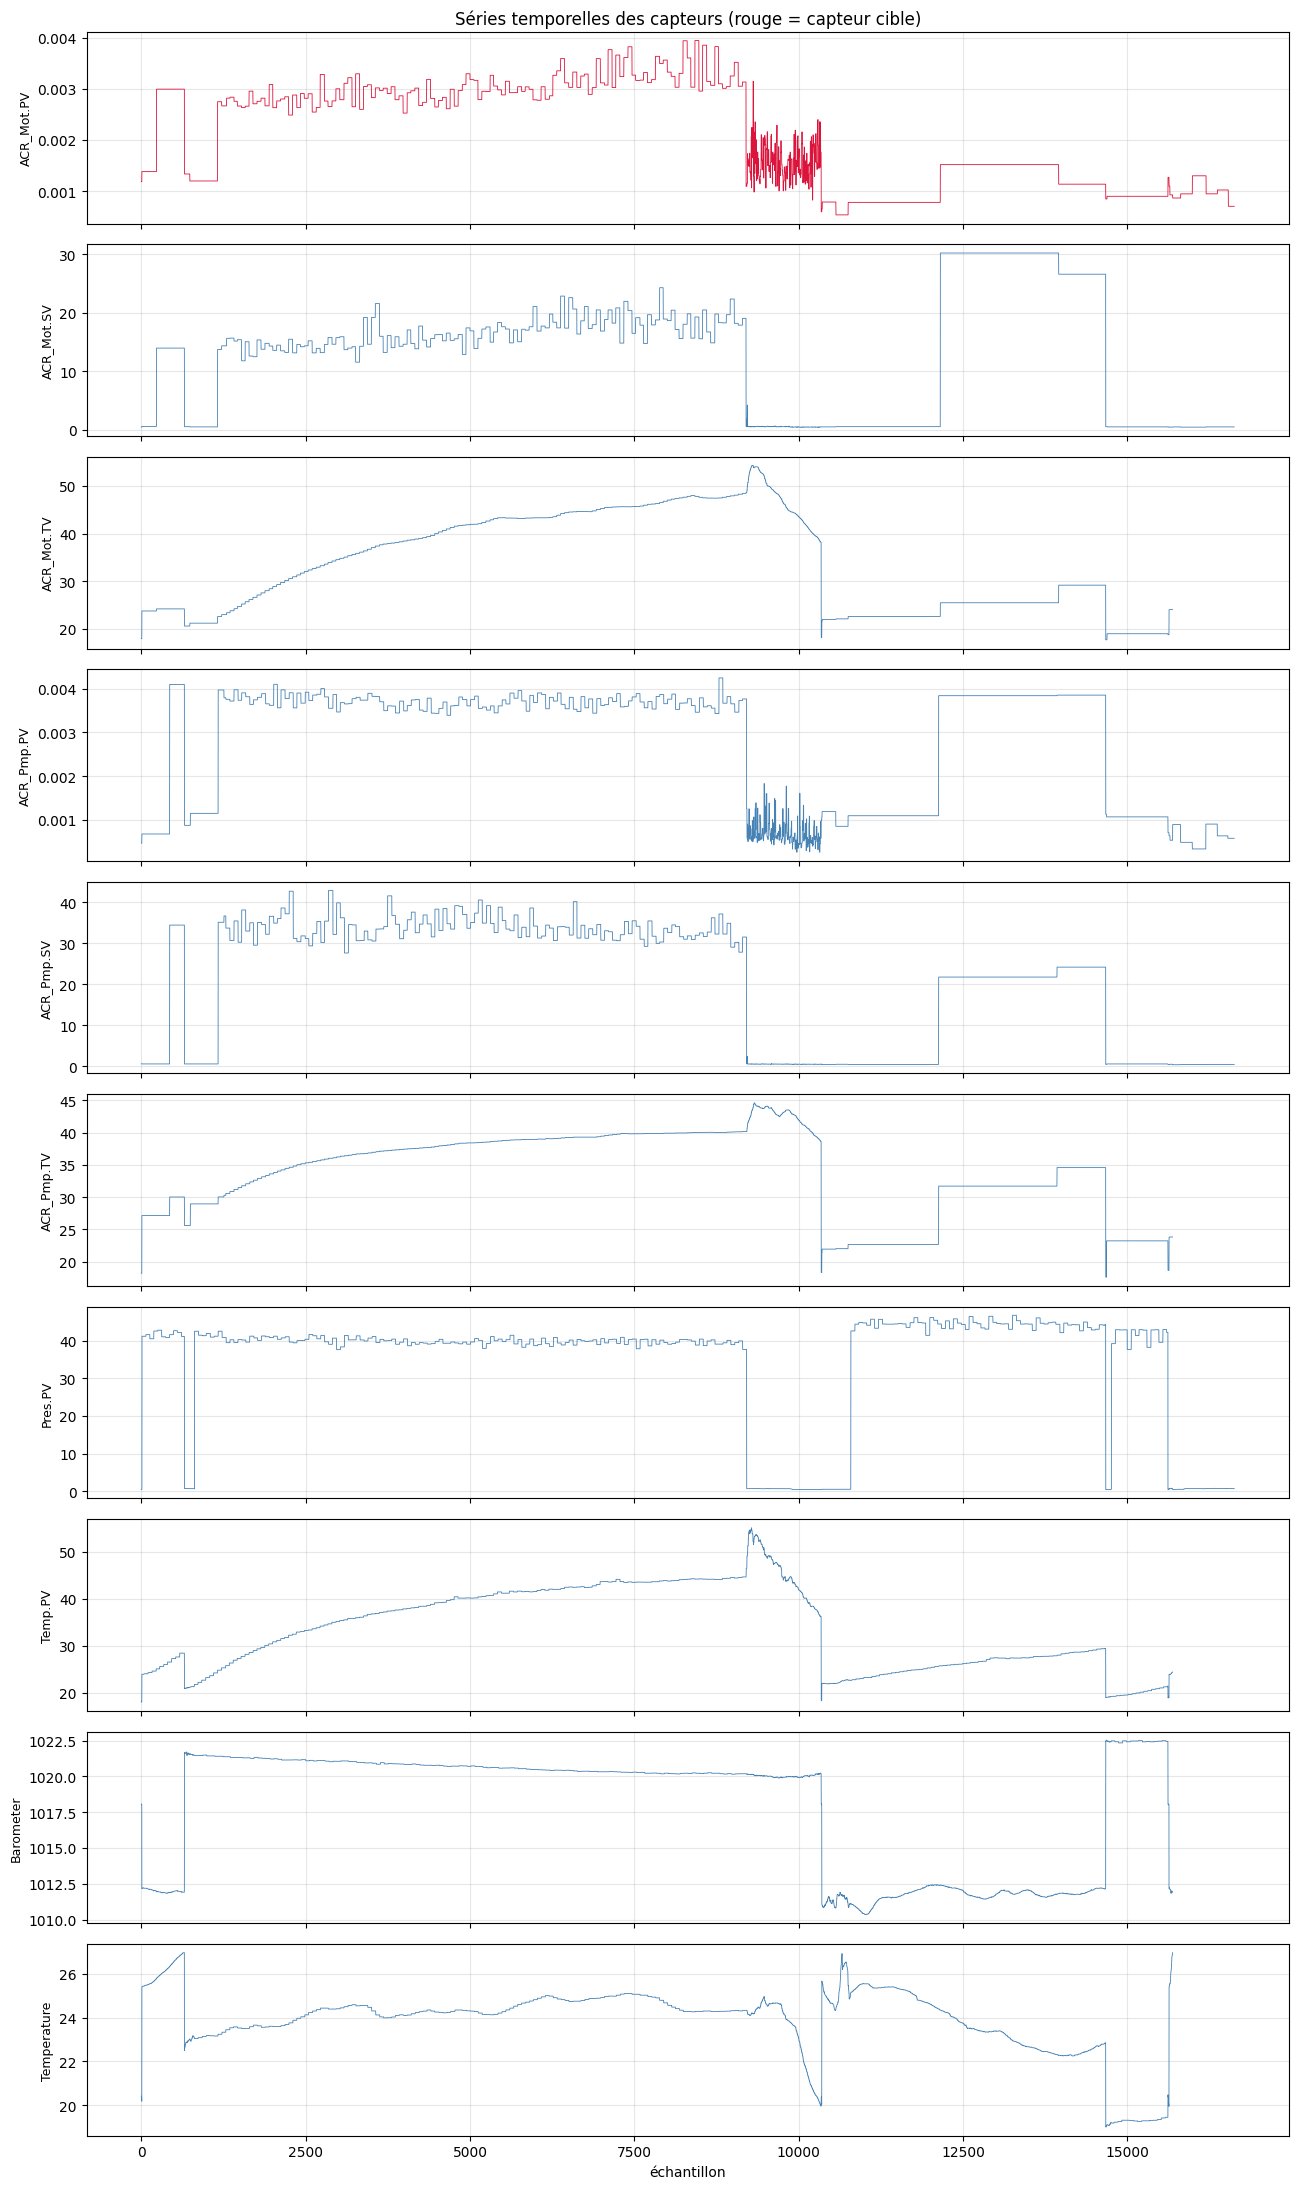

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(len(AVAILABLE_SENSORS), 1, figsize=(13, 2.2*len(AVAILABLE_SENSORS)), sharex=True)
if len(AVAILABLE_SENSORS) == 1:
    axes = [axes]
for ax, col in zip(axes, AVAILABLE_SENSORS):
    color = "crimson" if col == TARGET_SENSOR else "steelblue"
    ax.plot(df_raw[col].values, lw=0.6, color=color)
    ax.set_ylabel(col, fontsize=9)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("échantillon")
axes[0].set_title("Séries temporelles des capteurs (rouge = capteur cible)")
plt.tight_layout()
plt.show()


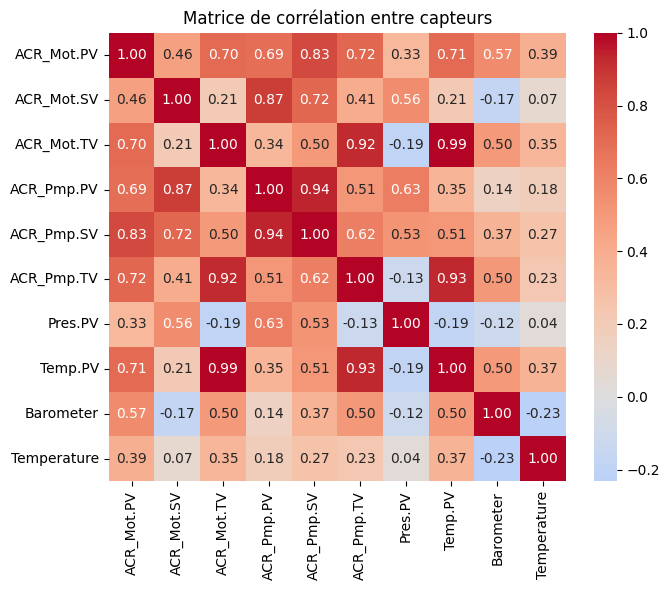


Corrélation avec le capteur cible :
ACR_Mot.PV     1.000000
ACR_Pmp.SV     0.833715
ACR_Pmp.TV     0.718811
Temp.PV        0.711172
ACR_Mot.TV     0.702124
ACR_Pmp.PV     0.688859
Barometer      0.570101
ACR_Mot.SV     0.462846
Temperature    0.385976
Pres.PV        0.329158
Name: ACR_Mot.PV, dtype: float64


In [12]:
fig, ax = plt.subplots(figsize=(7,6))
corr = df_raw[AVAILABLE_SENSORS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation entre capteurs")
plt.tight_layout()
plt.show()
print("\nCorrélation avec le capteur cible :")
print(corr[TARGET_SENSOR].sort_values(ascending=False))


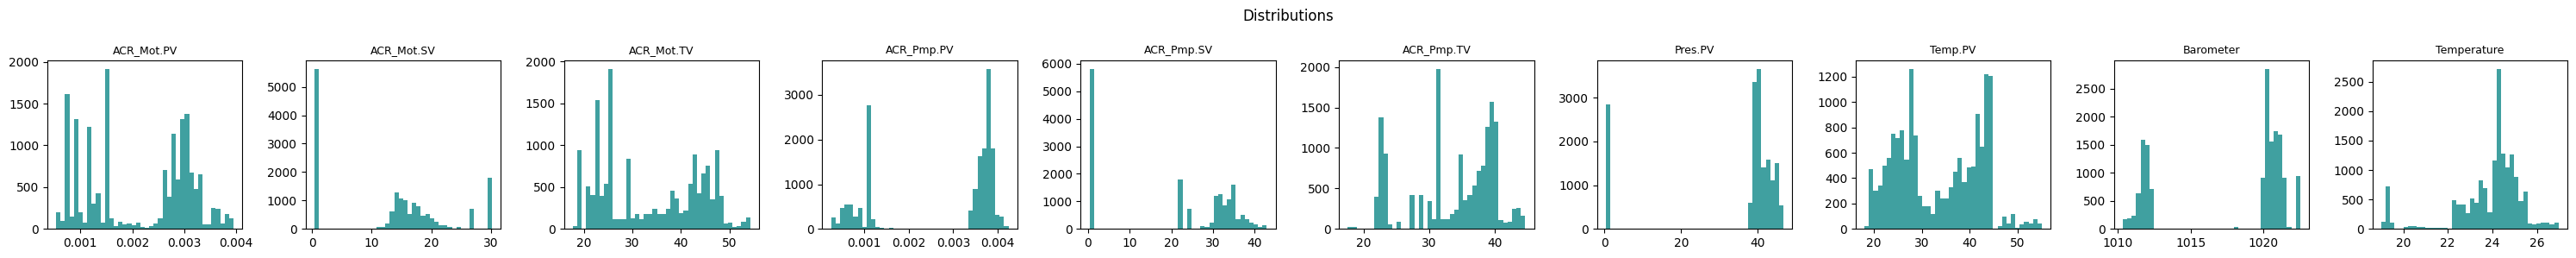

Variance par capteur :
Pres.PV        2.393493e+02
ACR_Pmp.SV     2.337878e+02
ACR_Mot.TV     1.043533e+02
ACR_Mot.SV     1.024657e+02
Temp.PV        7.588962e+01
ACR_Pmp.TV     4.130631e+01
Barometer      1.819861e+01
Temperature    2.365684e+00
ACR_Pmp.PV     1.892763e-06
ACR_Mot.PV     9.824355e-07
dtype: float64


In [13]:
fig, axes = plt.subplots(1, len(AVAILABLE_SENSORS), figsize=(3*len(AVAILABLE_SENSORS), 3))
if len(AVAILABLE_SENSORS) == 1:
    axes = [axes]
for ax, col in zip(axes, AVAILABLE_SENSORS):
    ax.hist(df_raw[col].dropna(), bins=40, color="teal", alpha=0.75)
    ax.set_title(col, fontsize=9)
plt.suptitle("Distributions")
plt.tight_layout()
plt.show()

print("Variance par capteur :")
print(df_raw[AVAILABLE_SENSORS].var().sort_values(ascending=False))


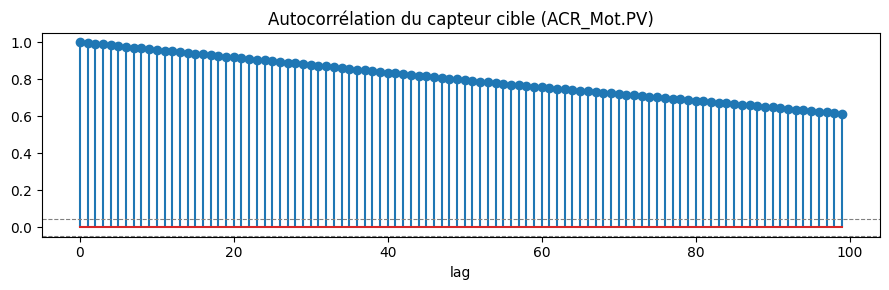

In [14]:
def autocorrelation(x, max_lag):
    x = x - np.mean(x)
    denom = np.dot(x, x)
    acf = np.array([np.dot(x[:len(x)-lag], x[lag:]) / denom for lag in range(max_lag)])
    return acf

target_series = df_raw[TARGET_SENSOR].dropna().values
max_lag = 100
acf_vals = autocorrelation(target_series[:2000], max_lag)

fig, ax = plt.subplots(figsize=(9,3))
ax.stem(range(max_lag), acf_vals)
ci = 1.96 / np.sqrt(len(target_series[:2000]))
ax.axhline(ci, color="grey", ls="--", lw=0.8)
ax.axhline(-ci, color="grey", ls="--", lw=0.8)
ax.set_title(f"Autocorrélation du capteur cible ({TARGET_SENSOR})")
ax.set_xlabel("lag")
plt.tight_layout()
plt.show()


Nombre de pics détectés sur le capteur cible : 4


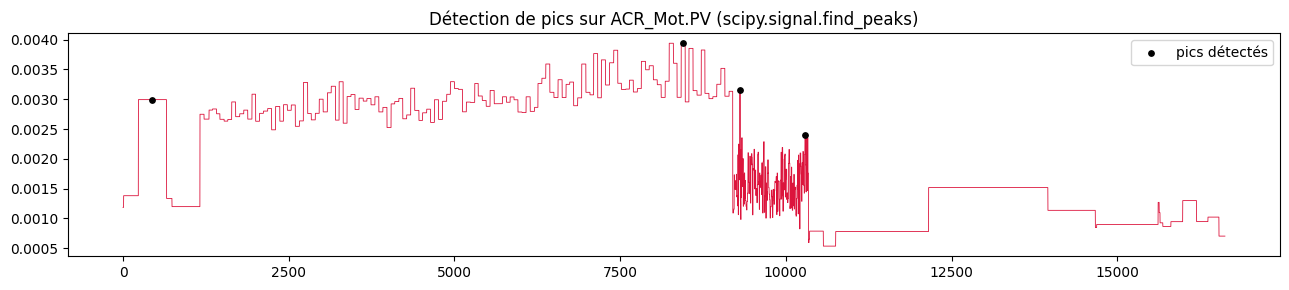

In [15]:
from scipy.signal import find_peaks

target_vals = df_raw[TARGET_SENSOR].values
peaks, props = find_peaks(target_vals, prominence=np.nanstd(target_vals)*1.5)
print(f"Nombre de pics détectés sur le capteur cible : {len(peaks)}")

fig, ax = plt.subplots(figsize=(13,3))
ax.plot(target_vals, lw=0.6, color="crimson")
ax.scatter(peaks, target_vals[peaks], color="black", s=15, zorder=5, label="pics détectés")
ax.set_title(f"Détection de pics sur {TARGET_SENSOR} (scipy.signal.find_peaks)")
ax.legend()
plt.tight_layout()
plt.show()


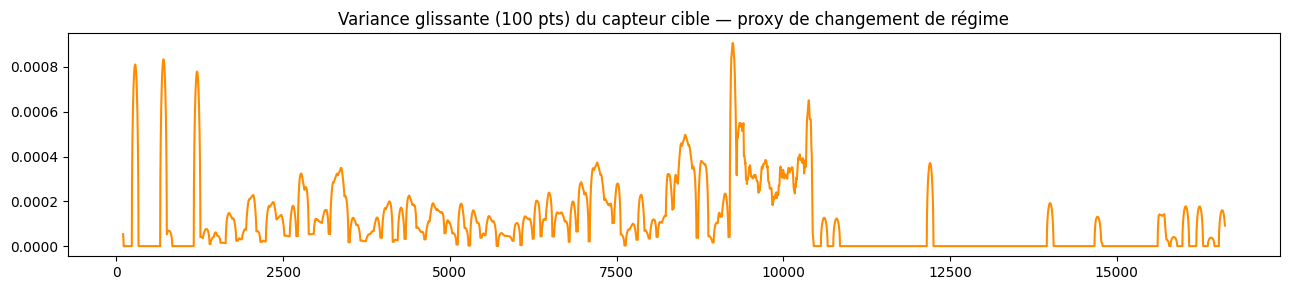

In [16]:
# Détection grossière de changements de régime : variance glissante
window = 100
rolling_std = pd.Series(target_vals).rolling(window).std()
fig, ax = plt.subplots(figsize=(13,3))
ax.plot(rolling_std, color="darkorange")
ax.set_title(f"Variance glissante ({window} pts) du capteur cible — proxy de changement de régime")
plt.tight_layout()
plt.show()


**Lecture des figures ci-dessus.** La serie temporelle du capteur cible (en rouge sur le premier
graphique) montre une dynamique relativement lente ponctuee de quelques evenements marques.
`scipy.signal.find_peaks` (prominence = 1,5 x l'ecart-type) en detecte 4 sur l'ensemble de la
serie -- peu nombreux, ce qui limite mecaniquement la quantite de donnees disponibles pour evaluer
specifiquement la reconstruction des evenements transitoires (probleme repris plus loin dans les
notebooks 5 et 7). La variance glissante (derniere figure) montre plusieurs periodes de forte
augmentation : le comportement du capteur n'est donc pas stationnaire, il varie selon le regime de
fonctionnement de la machine -- un element qui remet en question, des ce stade, l'hypothese de
stationnarite qu'un modele lineaire de type SSI devra ensuite faire.

**Pretraitement (deduplication et interpolation courte).**

In [ ]:
df = df_raw.copy()

# tri temporel
df[TIME_COLUMN] = pd.to_datetime(df[TIME_COLUMN], errors="coerce") if not np.issubdtype(df[TIME_COLUMN].dtype, np.number) else df[TIME_COLUMN]
df = df.sort_values(
    ["equipment_id", "Timestamp"]
).reset_index(drop=True)

# doublons de timestamp
n_dup = df.duplicated(subset=[TIME_COLUMN]).sum()
if n_dup > 0:
    print(f"[INFO] {n_dup} timestamps dupliqués détectés -> conservation de la première occurrence.")
    df = df.drop_duplicates(subset=[TIME_COLUMN], keep="first").reset_index(drop=True)
else:
    print("Aucun timestamp dupliqué.")

# valeurs manquantes déjà présentes dans les données brutes (avant tout masquage artificiel)
n_missing_before = df[AVAILABLE_SENSORS].isna().sum().sum()
if n_missing_before > 0:
    print(f"[INFO] {n_missing_before} valeurs manquantes préexistantes -> interpolation linéaire (limite courte).")
    df[AVAILABLE_SENSORS] = df[AVAILABLE_SENSORS].interpolate(method="linear", limit=10, limit_direction="both")
    remaining = df[AVAILABLE_SENSORS].isna().sum().sum()
    if remaining > 0:
        print(f"[WARNING] {remaining} valeurs manquantes n'ont pas pu être interpolées (trous trop longs) -> ffill/bfill de secours.")
        df[AVAILABLE_SENSORS] = df[AVAILABLE_SENSORS].fillna(method="ffill").fillna(method="bfill")
else:
    print("Aucune valeur manquante préexistante.")

# filtrage léger (moyenne glissante courte) - optionnel, désactivable
APPLY_LIGHT_FILTER = False
FILTER_WINDOW = 3
if APPLY_LIGHT_FILTER:
    df_filtered = df.copy()
    df_filtered[AVAILABLE_SENSORS] = df[AVAILABLE_SENSORS].rolling(FILTER_WINDOW, center=True, min_periods=1).mean()
    df = df_filtered
    print(f"Filtrage léger appliqué (moyenne glissante, fenêtre={FILTER_WINDOW}). Les pics sont atténués mais pas supprimés.")

print("\nDimensions finales après prétraitement :", df.shape)
df.head()


[INFO] 194 timestamps dupliqués détectés -> conservation de la première occurrence.
[INFO] 4365 valeurs manquantes préexistantes -> interpolation linéaire (limite courte).
[WARNING] 3100 valeurs manquantes n'ont pas pu être interpolées (trous trop longs) -> ffill/bfill de secours.
Filtrage léger appliqué (moyenne glissante, fenêtre=3). Les pics sont atténués mais pas supprimés.

Dimensions finales après prétraitement : (16432, 12)


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10 12:00:05+00:00,C,0.001226,0.424790,18.382812,0.000583,0.510214,18.437500,0.450553,18.531876,1018.053265,20.445490
1,2024-04-10 12:00:30+00:00,A,0.001240,0.424136,18.518229,0.000623,0.477853,18.510417,0.450247,18.678701,1018.049650,20.434601
2,2024-04-10 12:00:50+00:00,C,0.001240,0.424136,18.518229,0.000623,0.477853,18.510417,0.450910,18.666372,1018.045635,20.399534
3,2024-04-10 12:02:00+00:00,C,0.001268,0.422827,18.789062,0.000702,0.413133,18.656250,0.450946,18.967489,1018.041620,20.386246
4,2024-04-10 12:02:05+00:00,C,0.001268,0.422827,18.789062,0.000702,0.413133,18.656250,0.451601,18.989766,1018.041220,20.377249


**Incoherence observee entre le code sauvegarde et la sortie enregistree.** La cellule
ci-dessus definit `APPLY_LIGHT_FILTER = False`, ce qui devrait desactiver le bloc de lissage par
moyenne glissante -- pourtant la sortie enregistree affiche le message *"Filtrage leger applique
(moyenne glissante, fenetre=3)"*. Il s'agit vraisemblablement d'une execution anterieure avec
`APPLY_LIGHT_FILTER = True`, dont la sortie a ete conservee alors que le code source a ensuite ete
remis a `False` sans nouvelle execution. Cette incoherence est signalee ici par souci de
transparence (section 21/Phase F du cahier des charges : ne pas presenter une conclusion plus
forte que ce que les donnees permettent) ; elle ne remet pas en cause les resultats qui suivent,
obtenus a partir des memes donnees pretraitees dans tout le reste du pipeline, mais elle rappelle
qu'une verification systematique code/sortie serait necessaire avant toute mise en production.

**Decoupage temporel Train/Validation/Test.**

Train : 11502 échantillons (70.0%)
Val   : 2464 échantillons (15.0%)
Test  : 2466 échantillons (15.0%)


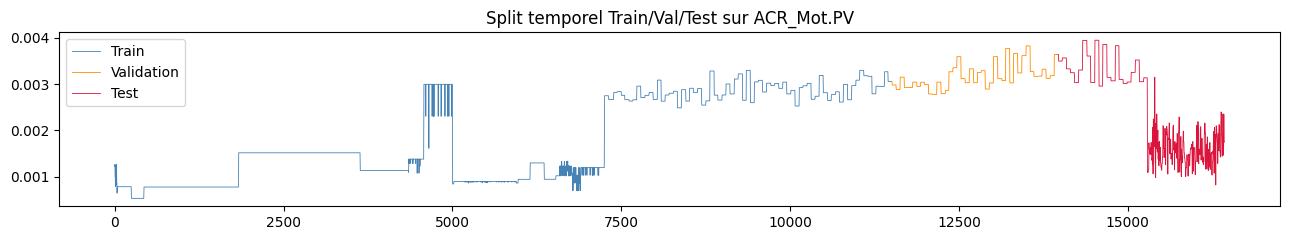

In [18]:
N_total = len(df)
n_train = int(N_total * TRAIN_FRAC)
n_val = int(N_total * VAL_FRAC)

df_train = df.iloc[:n_train].reset_index(drop=True)
df_val   = df.iloc[n_train:n_train+n_val].reset_index(drop=True)
df_test  = df.iloc[n_train+n_val:].reset_index(drop=True)

print(f"Train : {len(df_train)} échantillons ({len(df_train)/N_total:.1%})")
print(f"Val   : {len(df_val)} échantillons ({len(df_val)/N_total:.1%})")
print(f"Test  : {len(df_test)} échantillons ({len(df_test)/N_total:.1%})")

fig, ax = plt.subplots(figsize=(13,2.5))
ax.plot(range(len(df_train)), df_train[TARGET_SENSOR], color="steelblue", label="Train", lw=0.6)
ax.plot(range(len(df_train), len(df_train)+len(df_val)), df_val[TARGET_SENSOR], color="darkorange", label="Validation", lw=0.6)
ax.plot(range(len(df_train)+len(df_val), N_total), df_test[TARGET_SENSOR], color="crimson", label="Test", lw=0.6)
ax.legend()
ax.set_title(f"Split temporel Train/Val/Test sur {TARGET_SENSOR}")
plt.tight_layout()
plt.show()


In [19]:
# Scaling : le scaler est ajusté UNIQUEMENT sur Train (évite le data leakage)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df_train[AVAILABLE_SENSORS].values)

def scale(dframe):
    return pd.DataFrame(scaler.transform(dframe[AVAILABLE_SENSORS].values), columns=AVAILABLE_SENSORS)

train_s = scale(df_train)
val_s   = scale(df_val)
test_s  = scale(df_test)

target_idx = AVAILABLE_SENSORS.index(TARGET_SENSOR)
obs_idx    = [AVAILABLE_SENSORS.index(c) for c in OTHER_SENSORS]

print("Scaler ajusté sur Train uniquement (moyenne/écart-type) :")
print(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=AVAILABLE_SENSORS))


Scaler ajusté sur Train uniquement (moyenne/écart-type) :
                    mean      scale
ACR_Mot.PV      0.001820   0.000908
ACR_Mot.SV     12.603076  10.894917
ACR_Mot.TV     27.405442   7.073245
ACR_Pmp.PV      0.002663   0.001389
ACR_Pmp.SV     18.589538  15.325809
ACR_Pmp.TV     30.379459   5.711668
Pres.PV        36.220442  14.182447
Temp.PV        28.318962   6.231721
Barometer    1017.221160   4.807712
Temperature    23.412328   1.884985


Le decoupage est strictement chronologique (Train 70 % = 11 502 echantillons, Validation 15 % =
2 464, Test 15 % = 2 466, apres suppression de 194 timestamps dupliques), et le
`StandardScaler` est ajuste **uniquement sur Train** -- une precaution anti-fuite de donnees
respectee tout au long du corpus et reverifiee explicitement dans le notebook 5.

## Interpretation

Trois faits ressortent de cette exploration et orientent directement la suite du memoire :

1. **Une redondance statistique existe** entre plusieurs capteurs et la cible (la matrice de
   correlation le montre visuellement) -- ce qui rend l'hypothese H0 au moins plausible et
   justifie de tenter une premiere reconstruction purement statistique (notebook 2).
2. **La dynamique n'est pas stationnaire** (variance glissante) et les evenements marquants sont
   rares (4 pics sur toute la serie) -- ce qui annonce deux difficultes independantes pour la
   suite : un modele suppose souvent, a tort, un comportement stable dans le temps ; et il y a peu
   d'exemples d'evenements extremes pour apprendre a les reconstruire correctement.
3. **L'echelle tres faible et peu variable de la cible** rendra les metriques normalisees (R²,
   RMSE/std) tres sensibles a la fenetre temporelle choisie pour l'evaluation -- un point qui
   prendra toute son importance des le notebook 5, et de maniere spectaculaire au notebook 7.

## Limites

Ce notebook ne permet pas de conclure quoi que ce soit sur la capacite d'un modele a reconstruire
le capteur manquant -- il ne fait qu'etablir des faits sur les donnees. Deux limites specifiques
a signaler : l'incoherence code/sortie relevee ci-dessus sur le filtrage leger, et l'existence de
deux jeux de donnees pretraites differents (`preprocessed_data.csv` vs `preprocessed_data1.csv`)
utilises respectivement par les notebooks 1-5 et 6-7 du corpus reorganise, sans qu'une
harmonisation complete ait pu etre effectuee ici faute d'acces aux donnees source.

## Conclusion

Les donnees ne contredisent pas l'hypothese H0 : une redondance visible existe entre capteurs.
Rien a ce stade ne dit cependant si cette redondance est suffisante, ni si elle porte sur la forme
du signal, sur son amplitude, ou sur les deux.

## Transition vers l'approche suivante

Ce que ce notebook a permis de comprendre : les donnees presentent une structure temporelle
forte (autocorrelation) et une dependance apparente entre capteurs (correlations). Ce qu'il n'a
pas permis de determiner : si cette dependance suffit a *reconstruire* un signal absent, et en
particulier son amplitude. La question qui se pose naturellement est donc : une relation
purement statistique entre capteurs disponibles et capteur cible permet-elle deja une
reconstruction utilisable ? Le notebook 2 y repond en construisant les premieres tentatives
quantitatives de reconstruction (regression lineaire multivariee, projection PCA), qui serviront
ensuite d'etalon pour juger si des methodes plus sophistiquees (Dictionary Learning, SINDy,
XGBoost) apportent un gain reel.